In [1]:
import sys
# Append the previous directory to the path
sys.path.append('../')

In [2]:
import numpy as np
import pandas as pd
from exp_utils import CounterPlotNice
from sklearn.ensemble import RandomForestClassifier

In [3]:
# Download wine dataset
! wget https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv

# Read wine dataset
wine = pd.read_csv('winequality-red.csv', sep=';')

X, y = wine.drop('quality', axis=1), wine['quality']

# Transform X to numpy
X  = X.to_numpy()
# Transform y to binary
y = np.where(y > 5, 1, 0)

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [4]:
# Make RF model for noisy dataset
model = RandomForestClassifier(random_state=42)

In [5]:
model.fit(X, y)

RandomForestClassifier(random_state=42)

In [6]:
exp_nice = CounterPlotNice(
    predict_fn=model.predict_proba,
    X_train=X,
    y_train=y,
    cat_feat=[]
    )

In [27]:
# Select case with negative countershapley value
x_cs = exp_nice.explain(
    np.array([X[533]]),
    sample_size=None
    )

In [28]:
# Show countershapley values
countershapley_values = x_cs[0].countershapley_values()
countershapley_values

{'feature_names': ['f5', 'f9', 'f4', 'f6', 'f8', 'f7', 'f3'],
 'feature_values': (0.16250000000000003,
  0.12916666666666665,
  0.07083333333333332,
  0.04333333333333332,
  0.03333333333333331,
  0.023333333333333338,
  -0.03249999999999999),
 'feature_indices': (4, 8, 3, 5, 7, 6, 2)}

In [92]:
sample_sizes = range(10, 100, 10)
estimate_deviations = {k: [] for k in countershapley_values['feature_names']}

for sample_size in sample_sizes:
    # Select case with negative countershapley value
    x_cs = exp_nice.explain(
        np.array([X[533]]),
        sample_size=sample_size
        )
    countershapley_estimates = x_cs[0].countershapley_values()
    for feat_name, estimate, real_val in zip(
        countershapley_estimates['feature_names'], 
        countershapley_estimates['feature_values'],
        countershapley_values['feature_values']
        ):
        dev = abs(estimate - real_val) / real_val
        estimate_deviations[feat_name].append(dev)

Text(0.5, 0, 'Sample size (% of max)')

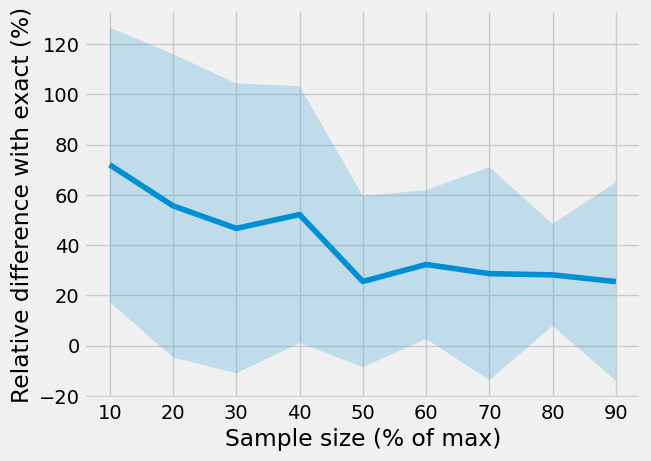

In [96]:
import matplotlib.pyplot as plt
plt.style.use("fivethirtyeight")

estimate_deviations_values = np.asarray(list(estimate_deviations.values()))
m, s = estimate_deviations_values.mean(axis=0), estimate_deviations_values.std(axis=0)

fig, ax = plt.subplots()
plt.plot(sample_sizes, 100*m)
plt.fill_between(sample_sizes, 100*(m-s), 100*(m+s), alpha=.2)

plt.ylabel("Relative difference with exact (%)")
plt.xlabel("Sample size (% of max)")